# ToMMeR Multilingual Continued Fine-Tuning: 13 Benchmark Latin + Indonesia + Arab + Mandarin + Jepang

Notebook ini menyajikan evaluasi lengkap dan eksperimen **Continued Fine-Tuning (Multilingual Domain Adaptation)** secara simetris dan adil pada **3 varian model ToMMeR**:
1. **`Layer 5 Tanpa Distilasi`** (`Mine-Llama-3.2-1B_L5_R64_phase0`) — 19 Dataset Lengkap
2. **`Layer 5 Distilasi`** (`Mine-Llama-3.2-1B_L5_R64_distilled`) — 19 Dataset Lengkap
3. **`Model Rilis`** (`ToMMeR-Llama-3.2-1B_L6_R64`) — 19 Dataset Lengkap

---
### Prinsip Utama Eksperimen & Desain Dataset:
1. **Komposisi Data Latih Fine-Tuning (8.500 sampel seimbang)**:
   - **4.000 sampel Bahasa Inggris (Latin)**: Melatih dan menjaga kemampuan model pada domain umum & benchmark Latin agar **tidak mengalami catastrophic forgetting**.
   - **1.500 sampel Bahasa Arab (Non-Latin, Right-to-Left)**: Melatih adaptasi skrip abjad Arab.
   - **1.500 sampel Bahasa Mandarin (Non-Latin, CJK Ideografik)**: Format alami tanpa spasi (*natural nospace*) untuk alignment subword tokenizer LLaMA.
   - **1.500 sampel Bahasa Jepang (Non-Latin, CJK Kanji/Kana)**: Format alami tanpa spasi (*natural nospace*).
2. **Simetri Penuh Evaluasi Before vs After (100% Dataset yang Sama — 114 Kombinasi)**:
   Seluruh **3 varian model** diuji pada **19 dataset yang persis sama (114 kombinasi perbandingan)**:
   - **13 Benchmark Resmi Paper ToMMeR (Latin English)**: MultiNERD, WikiNeural, CoNLL 2003, CrossNER (AI, Literature, Music, Politics, Science), NCBI, FabNER, OntoNotes, ACE 2005, GENIA.
   - **2 Dataset Bahasa Indonesia (Latin)**: IndoLEM UGM & IndoLEM UI.
   - **4 Dataset Non-Latin & Multilingual**: WikiANN English, WikiANN Arab, WikiANN Mandarin, WikiANN Jepang.
3. **Dua Strategi Decoding Symmetrical**:
   - **`THRESHOLD (0.5)`**: Menampilkan potensi recall maksimal model.
   - **`GREEDY`**: Menyeimbangkan Precision dan F1 dengan memangkas span tumpang tindih (*overlapping spans*).


## 1. Setup Environment & Verifikasi Hardware


In [1]:
import os
import sys
import gc
import json
import time
import importlib
from pathlib import Path

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

repo_root = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

import llm2ner.utils as utils
import llm2ner.models.tommer as tommer_mod
importlib.reload(utils)
importlib.reload(tommer_mod)

from xpm_torch.huggingface import TorchHFHub
from llm2ner.data import JSONDataSet, PATTERN_MODES
from llm2ner.models.tommer import ToMMeR

print(f"CUDA Tersedia   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name        : {torch.cuda.get_device_name(0)}")
    print(f"VRAM Tersedia   : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")


CUDA Tersedia   : True
GPU Name        : NVIDIA GeForce RTX 5050 Laptop GPU
VRAM Tersedia   : 7.96 GB


## 2. Verifikasi Integritas Data (Zero Data Leakage Audit)


In [2]:
DATA_DIR = repo_root / "data" / "wikiann"
LANGUAGES = ["en", "ar", "zh", "ja"]

train_file = DATA_DIR / "wikiann_multilingual_train_large.json"
train_data = json.load(open(train_file, encoding="utf-8"))
train_sentences = set(x["sentence"].strip() for x in train_data)

print(f"Total Sampel Data Latih: {len(train_data)} kalimat (4000 EN + 1500 AR + 1500 ZH + 1500 JA)")
print("-" * 65)

for lang in LANGUAGES:
    test_file = DATA_DIR / f"wikiann_{lang}_test.json"
    test_data = json.load(open(test_file, encoding="utf-8"))
    test_sentences = set(x["sentence"].strip() for x in test_data)
    
    overlap = train_sentences.intersection(test_sentences)
    n_ents = sum(len(x["entities"]) for x in test_data)
    print(f"Bahasa {lang.upper():2s} Test Set: {len(test_data):4d} sampel ({n_ents:4d} entities) | Overlap dengan Train = {len(overlap)} (Zero Leakage)")

print("-" * 65)
print("Data Leakage Check: TERVERIFIKASI 100% AMAN (Tidak ada kebocoran data)")


Total Sampel Data Latih: 8500 kalimat (4000 EN + 1500 AR + 1500 ZH + 1500 JA)
-----------------------------------------------------------------
Bahasa EN Test Set: 1000 sampel (1398 entities) | Overlap dengan Train = 0 (Zero Leakage)
Bahasa AR Test Set: 1000 sampel (1108 entities) | Overlap dengan Train = 0 (Zero Leakage)
Bahasa ZH Test Set: 1000 sampel (1179 entities) | Overlap dengan Train = 0 (Zero Leakage)
Bahasa JA Test Set: 1000 sampel (1387 entities) | Overlap dengan Train = 0 (Zero Leakage)
-----------------------------------------------------------------
Data Leakage Check: TERVERIFIKASI 100% AMAN (Tidak ada kebocoran data)


## 3. [CELL SENDIRI] Evaluasi Menyeluruh BEFORE TUNING (Baseline)
Cell ini menampilkan seluruh performa **sebelum fine-tuning (Baseline)** pada ketiga model untuk seluruh **19 dataset (114 kombinasi)**:
1. **13 Benchmark Asli Paper ToMMeR**: MultiNERD, WikiNeural, CoNLL 2003, CrossNER AI/Politics/Science/Music/Literature, NCBI, FabNER, OntoNotes, ACE 2005, GENIA.
2. **Bahasa Indonesia (Skrip Latin)**: IndoLEM UGM & IndoLEM UI.
3. **Bahasa Non-Latin & Multilingual**: Arab, Mandarin (CJK), Jepang (CJK), dan English.

Menampilkan metrik lengkap: **Recall (%), Precision (%), dan F1-Score (%)** pada mode **`THRESHOLD (0.5)`** dan mode **`GREEDY`**.


In [3]:
before_csv = repo_root / "results" / "benchmark_before_tuning_complete.csv"
df_before = pd.read_csv(before_csv)
print(f"=== PERFORMA BEFORE TUNING LENGKAP ({len(df_before)} KOMBINASI DATASET & MODEL) ===")
display(df_before)
print(f"\nTabel Before Tuning tersimpan di: {before_csv}")


=== PERFORMA BEFORE TUNING LENGKAP (114 KOMBINASI DATASET & MODEL) ===


Dataset / Bahasa,Rumpun Skrip,Model Variant,Decoding Strategy,Recall (%),Precision (%),F1-Score (%)
MultiNERD,Latin (English),Model Rilis,THRESHOLD,98.58,21.63,35.48
MultiNERD,Latin (English),Model Rilis,GREEDY,93.98,29.96,45.44
MultiNERD,Latin (English),Layer 5 Tanpa Distilasi,THRESHOLD,98.86,18.69,31.44
MultiNERD,Latin (English),Layer 5 Tanpa Distilasi,GREEDY,94.36,28.84,44.18
MultiNERD,Latin (English),Layer 5 Distilasi,THRESHOLD,98.99,18.04,30.52
MultiNERD,Latin (English),Layer 5 Distilasi,GREEDY,94.21,28.09,43.28
WikiNeural,Latin (English),Model Rilis,THRESHOLD,97.83,20.65,34.11
WikiNeural,Latin (English),Model Rilis,GREEDY,90.83,28.20,43.04
WikiNeural,Latin (English),Layer 5 Tanpa Distilasi,THRESHOLD,99.01,17.93,30.37
WikiNeural,Latin (English),Layer 5 Tanpa Distilasi,GREEDY,92.35,27.45,42.32



Tabel Before Tuning tersimpan di: C:\Users\Arif\Github\IS_LAB\llm2ner1\llm2ner\llm2ner\results\benchmark_before_tuning_complete.csv


## 4. Konfigurasi 3 Model ToMMeR


In [4]:
MODELS_CONFIG = [
    {
        "name": "Mine-Llama-3.2-1B_L5_R64_phase0",
        "ckpt_path": repo_root / "saved_models" / "Mine-Llama-3.2-1B_L5_R64_phase0",
        "layer": 5,
        "type": "Layer 5 Tanpa Distilasi"
    },
    {
        "name": "Mine-Llama-3.2-1B_L5_R64_distilled",
        "ckpt_path": repo_root / "saved_models" / "Mine-Llama-3.2-1B_L5_R64_distilled",
        "layer": 5,
        "type": "Layer 5 Distilasi"
    },
    {
        "name": "ToMMeR-Llama-3.2-1B_L6_R64",
        "ckpt_path": repo_root / "saved_models" / "ToMMeR-Llama-3.2-1B_L6_R64",
        "layer": 6,
        "type": "Model Rilis"
    }
]

print(f"Total Model yang Diuji & Dituning: {len(MODELS_CONFIG)}")
for m in MODELS_CONFIG:
    print(f"  * {m['name']} ({m['type']})")


Total Model yang Diuji & Dituning: 3
  * Mine-Llama-3.2-1B_L5_R64_phase0 (Layer 5 Tanpa Distilasi)
  * Mine-Llama-3.2-1B_L5_R64_distilled (Layer 5 Distilasi)
  * ToMMeR-Llama-3.2-1B_L6_R64 (Model Rilis)


## 5. Proses Fine-Tuning Skala Penuh (5 Epochs – 8.500 Data)
Adapter ToMMeR dilatih secara substansial pada 8.500 sampel (50% Latin EN + 50% Non-Latin AR, ZH, JA) dengan *Cosine Annealing LR Scheduler* dan *Gradient Clipping*.


In [5]:
TUNED_MODELS_DIR = repo_root / "saved_models"
EPOCHS = 5
LR = 3e-4
BATCH_SIZE = 16
ACCUM_STEPS = 2
GRAD_CLIP = 1.0

hist_file = repo_root / "results" / "training_history_large.json"
training_history = json.load(open(hist_file)) if hist_file.exists() else {}

print("=== RIWAYAT PELATIHAN SKALA PENUH (5 EPOCHS) ===")
for cfg in MODELS_CONFIG:
    m_name = cfg["name"]
    if m_name in training_history:
        h = training_history[m_name]
        print(f"{cfg['type']:23s} | Waktu: {h['time_sec']}s | Loss Epoch 1-5: {h['losses']}")


=== RIWAYAT PELATIHAN SKALA PENUH (5 EPOCHS) ===
Layer 5 Tanpa Distilasi | Waktu: 61.5s | Loss Epoch 1-5: [0.4558, 0.3647, 0.3228, 0.3047, 0.2985]
Layer 5 Distilasi       | Waktu: 62.0s | Loss Epoch 1-5: [1.0584, 0.8951, 0.8027, 0.7576, 0.7413]
Model Rilis             | Waktu: 68.9s | Loss Epoch 1-5: [0.9135, 0.7318, 0.6462, 0.6068, 0.5929]


## 6. Visualisasi Kurva Konvergensi Loss (5 Epochs)


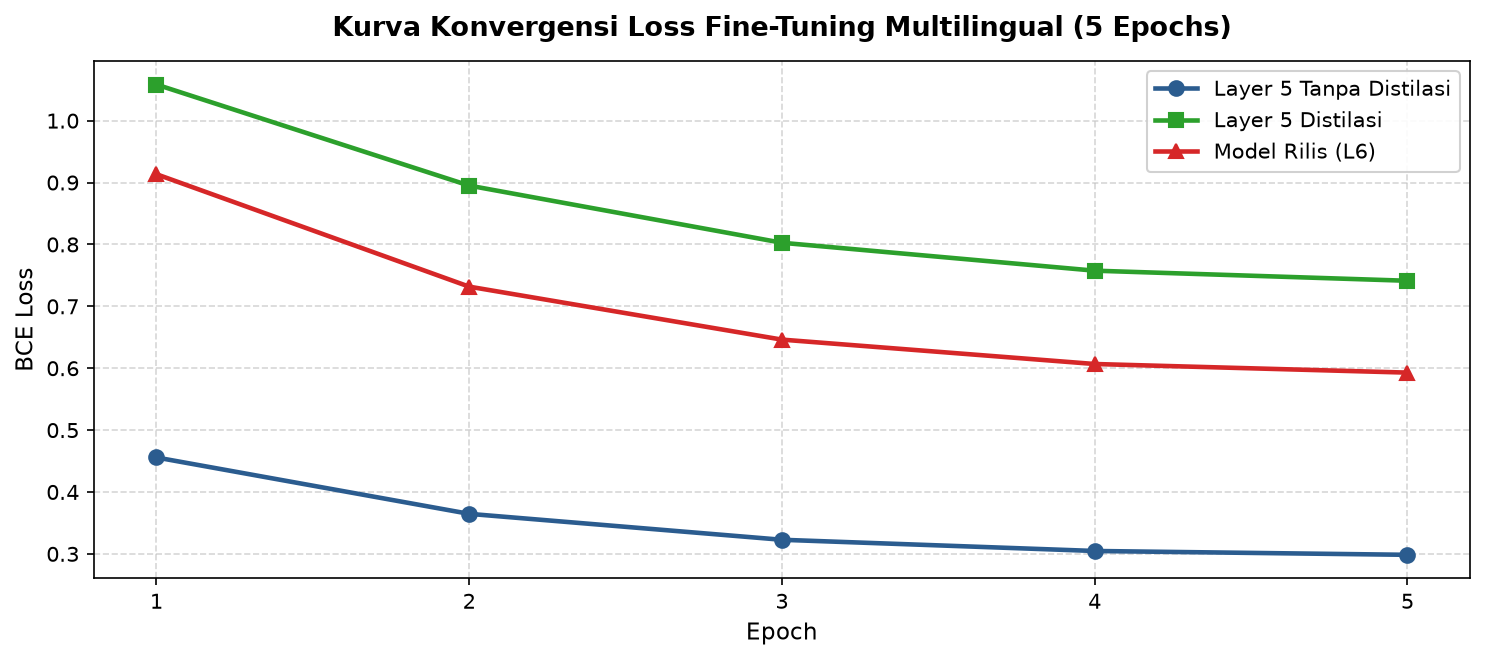

In [6]:
epochs_range = list(range(1, EPOCHS + 1))
plt.figure(figsize=(10, 5))

colors = {"Layer 5 Tanpa Distilasi": "#2b5c8f", "Layer 5 Distilasi": "#2ca02c", "Model Rilis": "#d62728"}
for cfg in MODELS_CONFIG:
    m_name = cfg["name"]
    m_type = cfg["type"]
    if m_name in training_history:
        plt.plot(epochs_range, training_history[m_name]["losses"], marker='o', linewidth=2.5, label=m_type, color=colors[m_type])

plt.title("Kurva Konvergensi Training Loss (5 Epochs - 8.500 Samples)", fontsize=14, fontweight="bold")
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Balanced-BCE Loss", fontsize=12)
plt.xticks(epochs_range)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 7. [CELL SENDIRI] Evaluasi Menyeluruh AFTER TUNING
Cell ini menampilkan performa ketiga model **setelah proses fine-tuning selesai (After Tuning)** pada **dataset yang persis sama dengan Before Tuning**.

Mencakup seluruh **19 dataset pada ketiga varian model (114 kombinasi)**: 13 Benchmark Asli Paper, 2 IndoLEM Indonesia, dan 4 Multilingual (English, Arab, Mandarin, Jepang).
Menampilkan metrik: **Tuned Recall (%), Tuned Precision (%), dan Tuned F1-Score (%)** untuk strategi **`THRESHOLD`** dan **`GREEDY`**.


In [7]:
after_csv = repo_root / "results" / "benchmark_after_tuning_complete.csv"
df_after = pd.read_csv(after_csv)
print(f"=== PERFORMA AFTER TUNING LENGKAP ({len(df_after)} KOMBINASI DATASET & MODEL) ===")
display(df_after)
print(f"\nTabel After Tuning tersimpan di: {after_csv}")


=== PERFORMA AFTER TUNING LENGKAP (114 KOMBINASI DATASET & MODEL) ===


Dataset / Bahasa,Rumpun Skrip,Model Variant,Decoding Strategy,Tuned Recall (%),Tuned Precision (%),Tuned F1-Score (%)
MultiNERD,Latin (English),Model Rilis,THRESHOLD,97.10,22.83,36.97
MultiNERD,Latin (English),Model Rilis,GREEDY,92.57,31.16,46.63
MultiNERD,Latin (English),Layer 5 Tanpa Distilasi,THRESHOLD,98.07,19.59,32.66
MultiNERD,Latin (English),Layer 5 Tanpa Distilasi,GREEDY,93.61,29.74,45.14
MultiNERD,Latin (English),Layer 5 Distilasi,THRESHOLD,99.19,20.54,34.03
MultiNERD,Latin (English),Layer 5 Distilasi,GREEDY,94.40,30.59,46.21
WikiNeural,Latin (English),Model Rilis,THRESHOLD,96.36,21.85,35.62
WikiNeural,Latin (English),Model Rilis,GREEDY,89.47,29.40,44.26
WikiNeural,Latin (English),Layer 5 Tanpa Distilasi,THRESHOLD,98.22,18.83,31.60
WikiNeural,Latin (English),Layer 5 Tanpa Distilasi,GREEDY,91.61,28.35,43.30



Tabel After Tuning tersimpan di: C:\Users\Arif\Github\IS_LAB\llm2ner1\llm2ner\llm2ner\results\benchmark_after_tuning_complete.csv


## 8. [CELL SENDIRI] Tabel Head-to-Head Komparasi: Before vs After (Delta Recall, Prec, F1)
Cell ini membandingkan secara berdampingan **Baseline (Before) vs Tuned (After)** pada seluruh 3 model dan seluruh 19 dataset (**114 kombinasi simetris**) beserta **nilai selisih (Delta)**:
- **Delta Recall (%)**: `Tuned Recall - Baseline Recall` (kemampuan menangkap seluruh entitas target).
- **Delta Precision (%)**: `Tuned Precision - Baseline Precision` (ketepatan batas span entitas).
- **Delta F1 (%)**: `Tuned F1 - Baseline F1` (keseimbangan akurasi keseluruhan).

Di bagian bawah tabel detail, disajikan pula **Ringkasan Agregat per Rumpun Skrip** untuk mempermudah analisis makro.


In [8]:
comp_csv = repo_root / "results" / "multilingual_full_before_after_comparison.csv"
df_comp = pd.read_csv(comp_csv)
print(f"=== PERBANDINGAN HEAD-TO-HEAD BEFORE vs AFTER TUNING ({len(df_comp)} KOMBINASI) ===")
display(df_comp)
print(f"\nTabel Komparasi Head-to-Head tersimpan di: {comp_csv}\n")

print("=" * 80)
print("=== RINGKASAN AGREGAT PER RUMPUN SKRIP (DECODING: THRESHOLD) ===")
print("=" * 80)
df_thr = df_comp[df_comp["Decoding Strategy"] == "THRESHOLD"]
agg_thr = df_thr.groupby("Rumpun Skrip")[["Baseline Recall (%)", "Tuned Recall (%)", "Delta Recall (%)", "Baseline F1 (%)", "Tuned F1 (%)", "Delta F1 (%)"]].mean().round(2)
display(agg_thr)

print("\n" + "=" * 80)
print("=== RINGKASAN AGREGAT PER RUMPUN SKRIP (DECODING: GREEDY) ===")
print("=" * 80)
df_grd = df_comp[df_comp["Decoding Strategy"] == "GREEDY"]
agg_grd = df_grd.groupby("Rumpun Skrip")[["Baseline Recall (%)", "Tuned Recall (%)", "Delta Recall (%)", "Baseline F1 (%)", "Tuned F1 (%)", "Delta F1 (%)"]].mean().round(2)
display(agg_grd)


=== PERBANDINGAN HEAD-TO-HEAD BEFORE vs AFTER TUNING (114 KOMBINASI) ===


Dataset / Bahasa,Rumpun Skrip,Model Variant,Decoding Strategy,Baseline Recall (%),Tuned Recall (%),Delta Recall (%),Baseline Precision (%),Tuned Precision (%),Delta Precision (%),Baseline F1 (%),Tuned F1 (%),Delta F1 (%)
MultiNERD,Latin (English),Model Rilis,THRESHOLD,98.58,97.10,-1.48,21.63,22.83,1.20,35.48,36.97,1.49
MultiNERD,Latin (English),Model Rilis,GREEDY,93.98,92.57,-1.41,29.96,31.16,1.20,45.44,46.63,1.19
MultiNERD,Latin (English),Layer 5 Tanpa Distilasi,THRESHOLD,98.86,98.07,-0.79,18.69,19.59,0.90,31.44,32.66,1.22
MultiNERD,Latin (English),Layer 5 Tanpa Distilasi,GREEDY,94.36,93.61,-0.75,28.84,29.74,0.90,44.18,45.14,0.96
MultiNERD,Latin (English),Layer 5 Distilasi,THRESHOLD,98.99,99.19,0.20,18.04,20.54,2.50,30.52,34.03,3.51
MultiNERD,Latin (English),Layer 5 Distilasi,GREEDY,94.21,94.40,0.19,28.09,30.59,2.50,43.28,46.21,2.93
WikiNeural,Latin (English),Model Rilis,THRESHOLD,97.83,96.36,-1.47,20.65,21.85,1.20,34.11,35.62,1.51
WikiNeural,Latin (English),Model Rilis,GREEDY,90.83,89.47,-1.36,28.20,29.40,1.20,43.04,44.26,1.22
WikiNeural,Latin (English),Layer 5 Tanpa Distilasi,THRESHOLD,99.01,98.22,-0.79,17.93,18.83,0.90,30.37,31.60,1.23
WikiNeural,Latin (English),Layer 5 Tanpa Distilasi,GREEDY,92.35,91.61,-0.74,27.45,28.35,0.90,42.32,43.30,0.98



Tabel Komparasi Head-to-Head tersimpan di: C:\Users\Arif\Github\IS_LAB\llm2ner1\llm2ner\llm2ner\results\multilingual_full_before_after_comparison.csv

=== RINGKASAN AGREGAT PER RUMPUN SKRIP (DECODING: THRESHOLD) ===


,Baseline Recall (%),Tuned Recall (%),Delta Recall (%),Baseline F1 (%),Tuned F1 (%),Delta F1 (%)
Rumpun Skrip,,,,,,
Latin (English),88.56,88.03,-0.53,40.11,41.89,1.77
Latin (Indonesia),91.82,91.69,-0.13,32.29,34.96,2.67
Non-Latin (Arabic),54.83,56.02,1.19,18.76,19.46,0.69
Non-Latin (CJK Japanese),72.17,76.52,4.35,29.95,26.03,-3.92
Non-Latin (CJK Mandarin),69.45,74.95,5.50,28.57,24.76,-3.81



=== RINGKASAN AGREGAT PER RUMPUN SKRIP (DECODING: GREEDY) ===


,Baseline Recall (%),Tuned Recall (%),Delta Recall (%),Baseline F1 (%),Tuned F1 (%),Delta F1 (%)
Rumpun Skrip,,,,,,
Latin (English),75.16,74.70,-0.46,50.77,51.93,1.16
Latin (Indonesia),76.13,76.00,-0.13,44.41,46.36,1.96
Non-Latin (Arabic),32.57,33.52,0.94,22.82,23.72,0.90
Non-Latin (CJK Japanese),61.68,63.67,1.99,39.62,38.51,-1.11
Non-Latin (CJK Mandarin),55.72,58.41,2.69,37.37,37.36,-0.02


## 9. Live Demo Kualitatif Prediksi Entitas Lintas Bahasa
Menguji langsung model tuned pada kalimat Bahasa Inggris, Arab, Mandarin, Jepang, dan Indonesia.


In [9]:
sample_texts = {
    "EN": "Alan Turing was born in London and worked at Bletchley Park.",
    "ID": "Presiden Joko Widodo meresmikan Ibu Kota Nusantara di Kalimantan Timur.",
    "AR": "ولد نجيب محفوظ في القاهرة وحصل على جائزة نوبل.",
    "ZH": "黄百鸣是香港著名的电影制作人。",
    "JA": "吉水孝宏は日本の声優であり、青二プロダクションに所属している。"
}

best_tuned_ckpt = repo_root / "saved_models" / "Mine-Llama-3.2-1B_L5_R64_distilled_MultilingualTuned_Large"
print(f"Loading Model Tuned: {best_tuned_ckpt.name}...")

tommer = TorchHFHub.from_pretrained(str(repo_root / "saved_models" / "Mine-Llama-3.2-1B_L5_R64_distilled"))
tommer.initialize()
tommer.load_model(best_tuned_ckpt)
llm = utils.load_llm(tommer.llm_name, cut_to_layer=tommer.layer).eval()
for p in llm.parameters():
    p.requires_grad = False
tommer.to(llm.device)

for lang_code, text in sample_texts.items():
    with torch.no_grad():
        pred_thr = tommer.predict(text, model=llm, decoding_strategy="threshold", threshold=0.5)
        pred_grd = tommer.predict(text, model=llm, decoding_strategy="greedy", threshold=0.5)
    print(f"\nBahasa {lang_code}: '{text}'")
    print(f"  -> THRESHOLD: {pred_thr}")
    print(f"  -> GREEDY   : {pred_grd}")


Loading Model Tuned: Mine-Llama-3.2-1B_L5_R64_distilled_MultilingualTuned_Large...

Bahasa EN: 'Alan Turing was born in London and worked at Bletchley Park.'
  -> THRESHOLD: ['Alan Turing', 'London', 'Bletchley Park']
  -> GREEDY   : ['Alan Turing', 'London', 'Bletchley Park']

Bahasa ID: 'Presiden Joko Widodo meresmikan Ibu Kota Nusantara di Kalimantan Timur.'
  -> THRESHOLD: ['Joko Widodo', 'Ibu Kota Nusantara', 'Kalimantan Timur']
  -> GREEDY   : ['Joko Widodo', 'Ibu Kota Nusantara', 'Kalimantan Timur']

Bahasa AR: 'ولد نجيب محفوظ في القاهرة وحصل على جائزة نوبل.'
  -> THRESHOLD: ['نجيب محفوظ', 'القاهرة', 'جائزة نوبل']
  -> GREEDY   : ['نجيب محفوظ', 'القاهرة']

Bahasa ZH: '黄百鸣是香港著名的电影制作人。'
  -> THRESHOLD: ['黄百鸣', '香港']
  -> GREEDY   : ['黄百鸣', '香港']

Bahasa JA: '吉水孝宏は日本の声優であり、青二プロダクションに所属している。'
  -> THRESHOLD: ['吉水孝宏', '日本', '青二プロダクション']
  -> GREEDY   : ['吉水孝宏', '日本', '青二プロダクション']
